# Q2B | Display the Statistical Values

> *Display the statistical values for each of the attributes, along with visualizations (ex: histogram) of the distributions for each attribute. Explain noticeable traits for key attributes. Are there any attributes that might require special treatment? If so, what special treatment might they require?*

---

#### IMPORTANT

This dataset has no `train` / `test` split of its own, so the split is made at the top of this notebook. It is chronological: the earliest 584 days are `train` and the latest 147 days are `test`. Every statistic below is computed on the training rows only, so no analysis or treatment decision is influenced by the test data (`data snooping`).

# Answer Summary

**Statistics and visualizations:** each continuous attribute below has a statistics table (center, spread, skew, kurtosis, IQR outliers, correlation with `Rentals`) and four plots (histogram w/ normal overlay, QQ plot, Rentals box plot split at a threshold, and a scatter against Rentals with linear, LOWESS, step and hinge fits). The target, `Rentals`, has the same statistics table (without the correlation) and the histogram and QQ plot only. Each categorical attribute has a level table (rows and the Rentals mean, median, std, min and max at each level) and two plots (rows per level, and a Rentals box plot per level with the level means R²). `Season` and `Month` also have a table that splits each level by `Year`.

**Noticeable traits**

- **The target, Rentals, is well behaved:** roughly symmetric (skew 0.067), mesokurtic (-0.675), with no outliers and no missing values. Its histogram has more than one peak.
- **Strength of the relationship with Rentals** (linear R² for the continuous attributes, level means R² for the categorical ones):
  - **Strongest:** FeelsLike (r = 0.69, R² 0.48), Temp (r = 0.685, R² 0.47) and Month (0.45).
  - **Clear:** Season (0.37) and Year (0.29).
  - **Weak:** Weather (0.10), Wind (r = -0.196, R² 0.04) and Humidity (r = -0.128, R² 0.02).
  - **None:** Weekday, IsWorkday and IsHoliday (all 0.00).
- **Temp and FeelsLike rise, then go flat.** LOWESS climbs up to about 0.6 and is flat above it. The hinge slopes are 9360.95 / -358.32 for Temp (bend at 0.58) and 9665.32 / -3086.80 for FeelsLike (bend at 0.60), and the hinge lifts R² from 0.47 to 0.52 and from 0.48 to 0.53.
- **Humidity only matters once it is high:** the hinge at 0.70 flips the slope from 1641.73 to -9191.70. It also has one isolated value of exactly 0.0.
- **Wind is the only skewed attribute** (0.668), with 12 high outliers that follow its gentle downward trend. No shape clearly beats the straight line (R² 0.04 to 0.06).
- **The categorical codes are labels, not amounts.** The Season and Month means rise and then fall across the codes (Season: 2,651 / 4,992 / 5,179 / 3,664), and the Weather means fall in unequal steps (4,510 / 3,665 / 1,820).
- **The second year runs higher:** a Rentals mean of 5,400 at Year 1 against 3,406 at Year 0, and 2092.583 to 2434.315 higher at each Season level that has both years.
- **The chronological split leaves the levels unevenly covered.** Train holds all of the first year and the second only up to 2012-08-06, so Season 4 and months 9 to 12 only have first-year rows. The test period (2012-08-07 to 2012-12-31) is those same months in the second year.
- **Rare levels:** IsHoliday level 1 (16 rows) and Weather level 3 (18 rows). Weather level 3 has the largest effect of any level (`mean - overall mean` of -2333.210).
- **No missing values in any of the 12 attributes below,** so nothing needs imputing. Every continuous table shows `missing 0`, and the rows in every level table add up to the 584 train rows.

**Special treatment:** yes. Every attribute's `Notes / Observations` section below ends with a `Special Treatment` list of the treatments it might require. The target needs none. The four columns without a section of their own (`ID`, `Date`, `Casual` and `Registered`) are covered in `Columns Without a Section` at the bottom.

---

# Imports

In [1]:
import pandas as pd
from IPython.display import display

from Q2.consts import *
from Q2.utils import chronological_split, Q2_STATISTICS, Q2_PLOTTING

from utils import (
	read_csv_to_df,
	STATISTICS,
	PLOTTING,
)

pd.set_option('display.max_rows', None)
pd.set_option('display.min_rows', None)
pd.set_option('display.max_columns', None)

# Fetch Data

In [2]:
df = read_csv_to_df(path=DATA_PATH, parse_dates=["dteday"])
df = df.rename(columns=SHORT_NAMES)

# Train / Test Split

In [3]:
train_df, test_df = chronological_split(df=df, date_col="Date", test_size=TEST_SIZE)

pd.DataFrame({
	"rows": [len(train_df), len(test_df)],
	"% of rows": [round(len(train_df) / len(df) * 100, 2), round(len(test_df) / len(df) * 100, 2)],
	"first date": [f"{train_df['Date'].min():%Y-%m-%d}", f"{test_df['Date'].min():%Y-%m-%d}"],
	"last date": [f"{train_df['Date'].max():%Y-%m-%d}", f"{test_df['Date'].max():%Y-%m-%d}"],
}, index=["train", "test"])

,rows,% of rows,first date,last date
train,584,79.89,2011-01-01,2012-08-06
test,147,20.11,2012-08-07,2012-12-31


# Statistical Values: Continuous Attributes

## How to Read the Plots (applies to every continuous attribute below)

- **Histogram w/ normal overlay:** the attribute's distribution against a normal curve with the same mean and SD. Gaps between the bars and the red curve show skew, values piling up at one end, or more than one peak.
- **QQ plot:** the sorted values against the values a normal distribution would produce. Points on the red line mean normal.
  - Low end below the line and high end above it: heavy tails. The reverse: light tails.
  - Points bowing above the line through the middle: left skew. Bowing below: right skew.
  - A flat run at one end: values piling up against a limit.
- **Box plot:** Rentals for the rows below vs at or above the step threshold. The further apart the boxes, the more a simple above/below split explains.
- **Scatter plot fits:**
  - **Linear (red):** the straight line. This is the only shape a raw attribute can give a linear regression.
  - **LOWESS (green):** a smoothed local average that does not assume a shape. When it bends away from the red line, the relationship is not linear and the raw attribute will underfit.
  - **Step (blue, dotted):** one mean on each side of a threshold. If its R² is close to the linear R², an above/below indicator carries most of the signal.
  - **Hinge (violet, dashed):** two straight segments joined at a threshold. If its R² beats the linear R², the attribute is a candidate for a hinge or spline term.
  - The step and hinge thresholds are searched on the same rows they are scored on, so their R² values are optimistic.

## Rentals (Target)

In [4]:
STATISTICS.statistics_df(series=train_df[TARGET])

,Rentals
count,584.0
missing,0
% missing,0.0
mean,4153.599
std,1788.888
min,431.0
25%,2806.5
50%,4200.0
75%,5219.0
max,8362.0


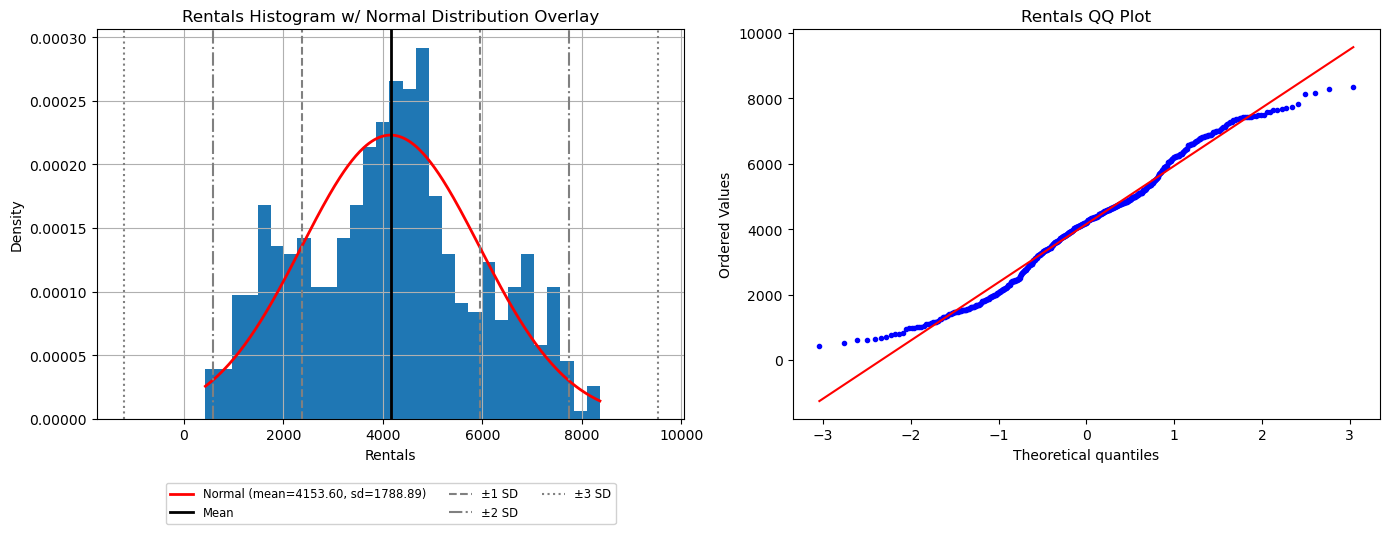

In [5]:
PLOTTING.distribution_plots(series=train_df[TARGET]);

### Notes / Observations

The target has no box plot or scatter plot, since those show an attribute against the target. Its table has no `corr with target` row for the same reason.

#### Noticeable Traits / Key Attributes

- **Roughly symmetric (skew 0.067) and mesokurtic (-0.675).** The mean (4153.599) and median (4200.0) are close, and half the values sit between 2806.5 and 5219.0.
- **Complete and clean:** no missing values and no outliers on either side (fences -812.25 and 8837.75), so no row has to be dropped or capped because of the target.
- **Wide range:** 431 to 8,362 rentals in a day, with a std of 1788.888.
- **Histogram:** more than one peak. The main peak is around 4,000 to 5,000, with a lower hump around 1,500 to 2,000 and a shoulder near 7,000.
- **QQ plot:** the points weave around the line instead of sitting on it, which matches the several peaks. The low end sits above the line and the high end below it (light tails).
- **More than one peak suggests the rows fall into groups with different Rentals levels.** That is something for the attributes to explain, not something to fix in the target.

#### Special Treatment

- **None needed.** There is no skew to fix, no outlier to handle and nothing to impute, so the target goes into the model as it is.

## Temp

In [6]:
STATISTICS.statistics_df(series=train_df['Temp'], target=train_df[TARGET])

,Temp
count,584.0
missing,0
% missing,0.0
mean,0.497
std,0.188
min,0.059
25%,0.336
50%,0.502
75%,0.66
max,0.862


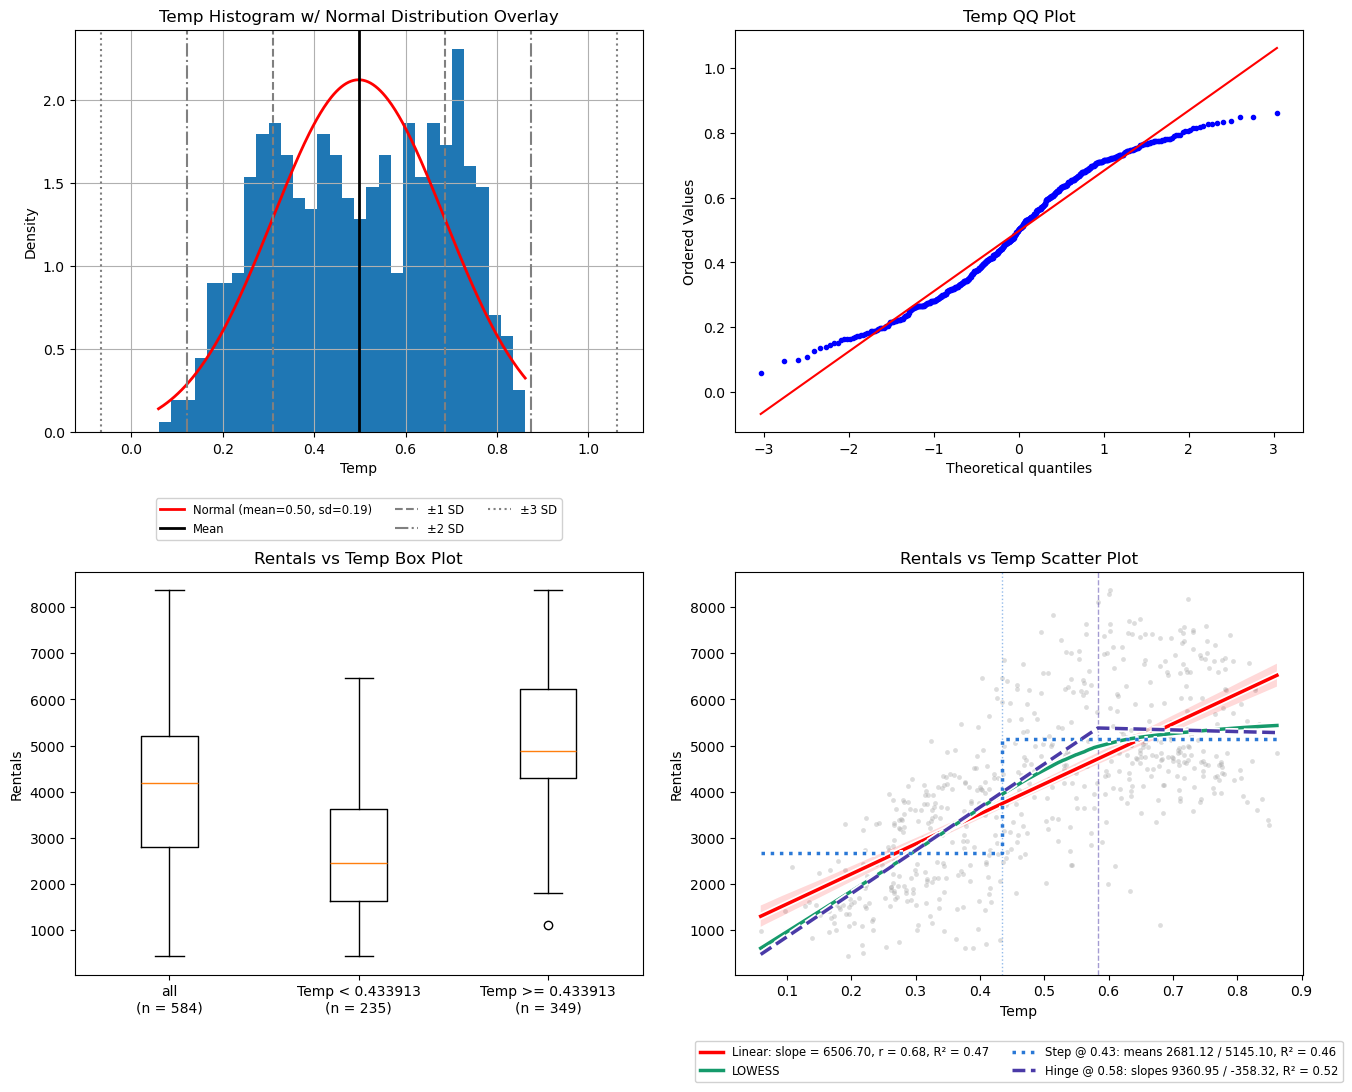

In [7]:
PLOTTING.single_feature_plots(df=train_df, feature='Temp', target=TARGET, threshold="auto");

### Notes / Observations

#### Noticeable Traits / Key Attributes

- **Roughly symmetric (-0.083) and platykurtic (-1.11).** The histogram is broad and flat topped, with two humps (around 0.3 and around 0.7) and no single peak at the mean of 0.497. In the QQ plot the low end sits above the line and the high end below it (light tails).
- **Complete and clean:** no missing values and no outliers on either side, with every value between 0.059 and 0.862.
- **Clear positive relationship:** r = 0.685 (R² 0.47).
- **Rises, then flattens.** LOWESS climbs steeply up to about 0.6 and is nearly flat above it. The hinge at 0.58 changes the slope from 9360.95 to -358.32 and lifts R² from 0.47 to 0.52, so above about 0.58 a higher value says almost nothing more about Rentals.
- **The straight line misses in a pattern.** It keeps rising where LOWESS is flat, so it sits above LOWESS at both ends (it overpredicts Rentals for the lowest and the highest values) and below it in the middle.
- **Both sides of the bend are well supported.** The bend at 0.58 sits between the median (0.502) and the 75% value (0.66), so more than a quarter of the rows are on the flat side.
- **A split alone comes close, but loses the slope.** The step at 0.43 (means 2681.12 / 5145.10) reaches R² 0.46, just under the linear R² of 0.47. In the box plot the 235 rows below 0.433913 have a median Rentals of about 2,450, vs about 4,900 for the 349 rows at or above it.

#### Special Treatment

Candidates, ranked by expected benefit:

1. **Replace the raw value with a flat top hinge alone:** `max(0, 0.58 - x)`, which is the same shape as capping the value at 0.58. One column with one slope below the bend and flat above it. The slope above the bend (-358.32) is tiny next to the slope below it (9360.95), so leaving the raw column out loses almost nothing.
2. **Raw value plus a hinge:** `[x, max(0, x - 0.58)]`. The same shape with a spare slope above the bend, at the cost of an extra column.
3. **A squared term** (what a degree 2 polynomial adds). It curves the right way and needs no threshold, but a smooth curve cannot go flat. It keeps bending and turns downward at the top.

- **Scaling:** standardize it before building polynomial terms. Every value is positive and below 1, so its powers all rise together and each one is smaller than the last.
- **Avoid an indicator alone.** The step R² (0.46) is below the linear R² (0.47) and the hinge R² (0.52), and it throws away the slope below the bend.
- **No skew or outlier treatment needed.**

## FeelsLike

In [8]:
STATISTICS.statistics_df(series=train_df['FeelsLike'], target=train_df[TARGET])

,FeelsLike
count,584.0
missing,0
% missing,0.0
mean,0.476
std,0.168
min,0.079
25%,0.336
50%,0.49
75%,0.615
max,0.841


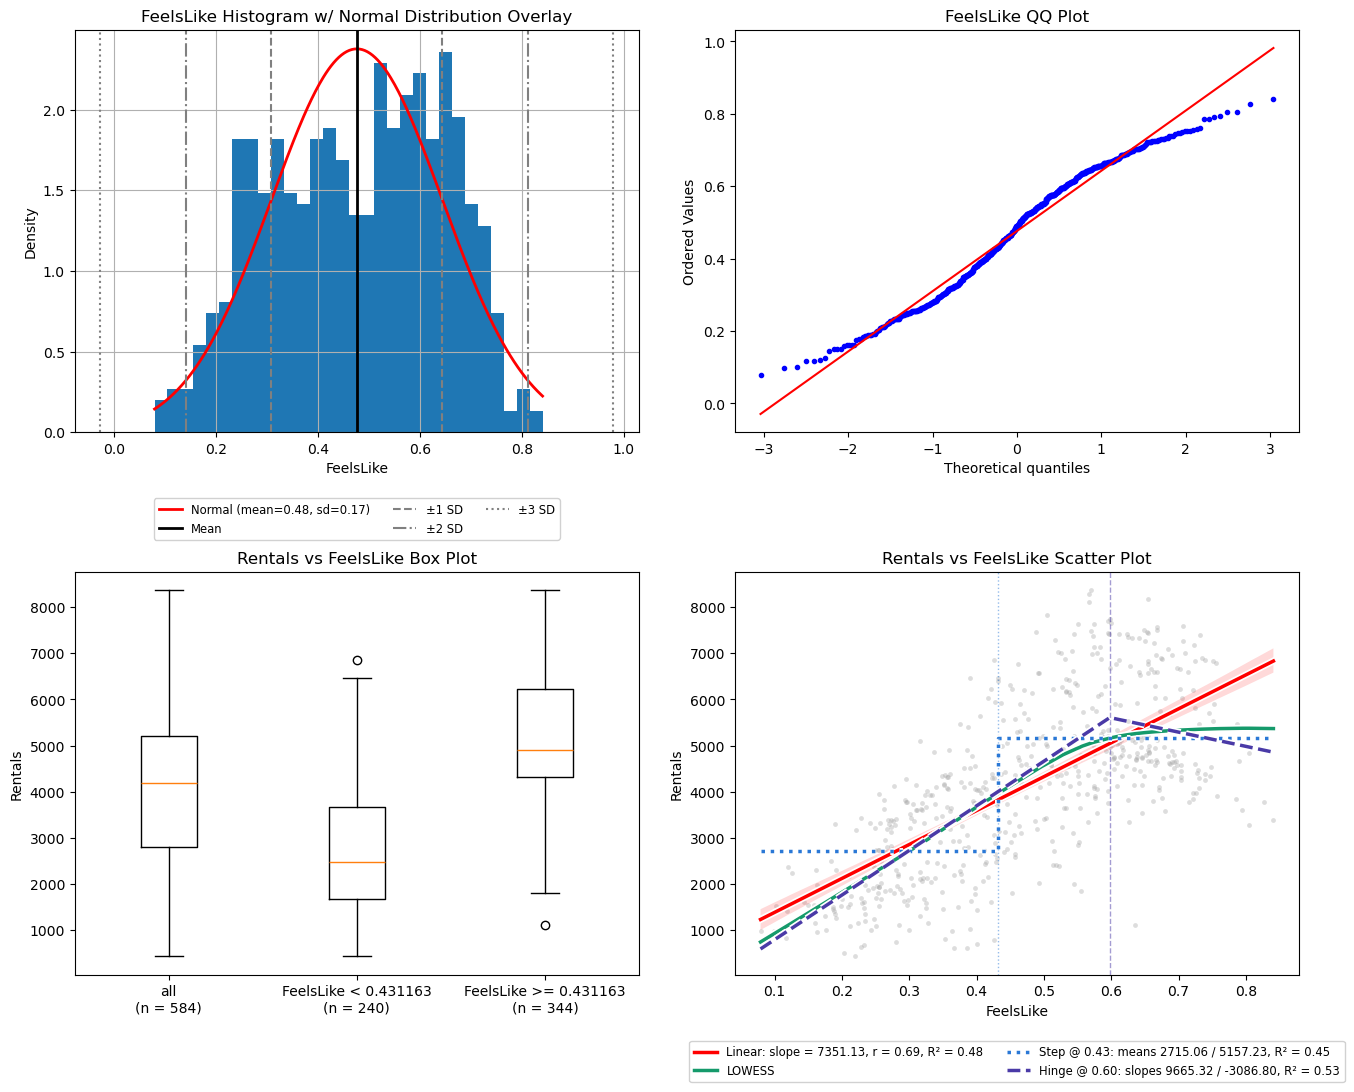

In [9]:
PLOTTING.single_feature_plots(df=train_df, feature='FeelsLike', target=TARGET, threshold="auto");

### Notes / Observations

#### Noticeable Traits / Key Attributes

- **Roughly symmetric (-0.156) and mesokurtic (-0.971).** The histogram is broad, with two humps (around 0.25 to 0.3 and around 0.55 to 0.65) and few values above about 0.75. In the QQ plot the low end sits above the line and the high end below it (light tails).
- **Complete and clean:** no missing values and no outliers on either side, with every value between 0.079 and 0.841.
- **Clear positive relationship:** r = 0.69 (R² 0.48).
- **Rises, then flattens.** LOWESS climbs steeply up to about 0.6 and is flat above it. The hinge at 0.60 changes the slope from 9665.32 to -3086.80 and lifts R² from 0.48 to 0.53.
- **The downturn at the top is not reliable.** The hinge turns downward above 0.60 (-3086.80), but LOWESS stays flat there, and the histogram shows few rows above about 0.75.
- **The straight line misses in a pattern.** It keeps rising where LOWESS is flat, so it sits above LOWESS at both ends (it overpredicts Rentals for the lowest and the highest values) and below it in the middle.
- **Both sides of the bend are supported.** The bend at 0.60 sits just below the 75% value (0.615), so a little more than a quarter of the rows are on the flat side.
- **A split alone is not enough.** The step at 0.43 (means 2715.06 / 5157.23) reaches R² 0.45, below the linear R² of 0.48. In the box plot the 240 rows below 0.431163 have a median Rentals of about 2,500, vs about 4,900 for the 344 rows at or above it.

#### Special Treatment

Candidates, ranked by expected benefit:

1. **Replace the raw value with a flat top hinge alone:** `max(0, 0.60 - x)`, which is the same shape as capping the value at 0.60. One column with one slope below the bend and flat above it. It follows LOWESS and leaves out the downturn that the thin top end suggests.
2. **Raw value plus a hinge:** `[x, max(0, x - 0.60)]`. It lets the top slope downward (-3086.80), which fits these rows slightly better but leans on the few rows at the top.
3. **A squared term** (what a degree 2 polynomial adds). It curves the right way and needs no threshold, but it also turns downward at the top, the same risk as 2.

- **Scaling:** standardize it before building polynomial terms. Every value is positive and below 1, so its powers all rise together and each one is smaller than the last.
- **Avoid an indicator alone.** The step R² (0.45) is below the linear R² (0.48) and the hinge R² (0.53), and it throws away the slope below the bend.
- **No skew or outlier treatment needed.**

## Humidity

In [10]:
STATISTICS.statistics_df(series=train_df['Humidity'], target=train_df[TARGET])

,Humidity
count,584.0
missing,0
% missing,0.0
mean,0.623
std,0.148
min,0.0
25%,0.507
50%,0.622
75%,0.73
max,0.972


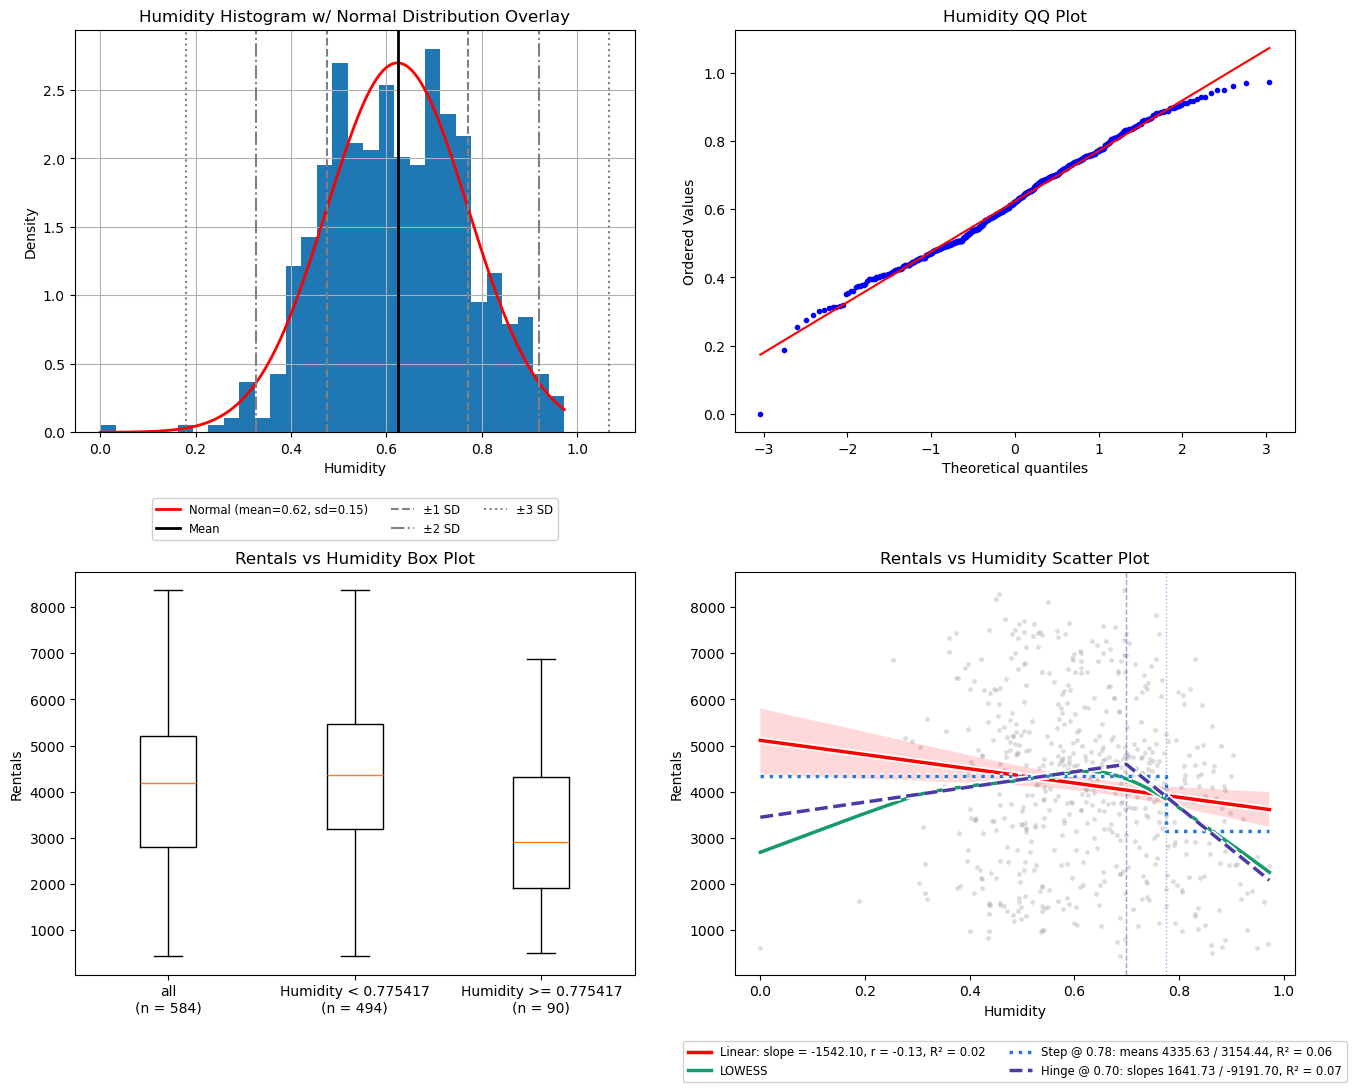

In [11]:
PLOTTING.single_feature_plots(df=train_df, feature='Humidity', target=TARGET, threshold="auto");

### Notes / Observations

#### Noticeable Traits / Key Attributes

- **Roughly symmetric (-0.071) and mesokurtic (-0.135).** The histogram follows the normal curve closely, and the QQ plot sits on the line except for the lowest point.
- **1 low outlier** below the 0.172 fence, and none above. It is the minimum, a value of exactly 0.0, and it stands alone: in the QQ plot the next lowest value is about 0.19. In the scatter plot that row has Rentals of about 600.
- **Weak negative relationship:** r = -0.128 (R² 0.02).
- **Only matters once it is high.** LOWESS rises gently up to about 0.65, then falls steeply. The hinge at 0.70 flips the slope from 1641.73 to -9191.70 (R² 0.07 vs 0.02).
- **The straight line averages two opposite slopes,** a gentle rise over most of the range and a steep fall at the top. That is why r is so small.
- **A split captures most of it.** The step at 0.78 (means 4335.63 / 3154.44) reaches R² 0.06, above the linear R² of 0.02 and close to the hinge. In the box plot the 90 rows at or above 0.775417 have a median Rentals of about 2,900, vs about 4,350 for the 494 rows below.
- **The falling side has fewer rows.** The bend at 0.70 is just below the 75% value (0.73), so a little more than a quarter of the rows sit above it.
- **The low end rests on little data.** Very few rows sit below about 0.3, and the band around the straight line is widest there.

#### Special Treatment

Candidates, ranked by expected benefit:

1. **Replace the raw value with a hinge alone:** `max(0, x - 0.70)`. One column that is flat below the bend and has one falling slope above it. The slope below the bend (1641.73) is small next to the slope above it (-9191.70), and part of it rests on the thin low end.
2. **An indicator for high values:** `1[x >= 0.78]`. One column, and the step R² (0.06) is close to the hinge R² (0.07). It cannot follow the fall continuing above 0.78, and it rests on 90 rows.
3. **A squared term** (what a degree 2 polynomial adds). It lets the line rise and then fall with no threshold, but the fall here is much steeper than the rise, which one squared term cannot match.

- **The 0.0 value:** with candidate 1 it sits in the flat part and has no pull on the fit, so the row can stay as it is. If the raw column is kept, it is the point furthest from the rest, so replacing it with the median (0.622) is a candidate.
- **Low value overall.** Even the best fit explains little (R² 0.07), and that value is optimistic because the threshold was searched on the same rows. If none of the candidates improves the model, leave it raw.
- **No skew treatment needed.**

## Wind

In [12]:
STATISTICS.statistics_df(series=train_df['Wind'], target=train_df[TARGET])

,Wind
count,584.0
missing,0
% missing,0.0
mean,0.194
std,0.076
min,0.022
25%,0.14
50%,0.186
75%,0.234
max,0.507


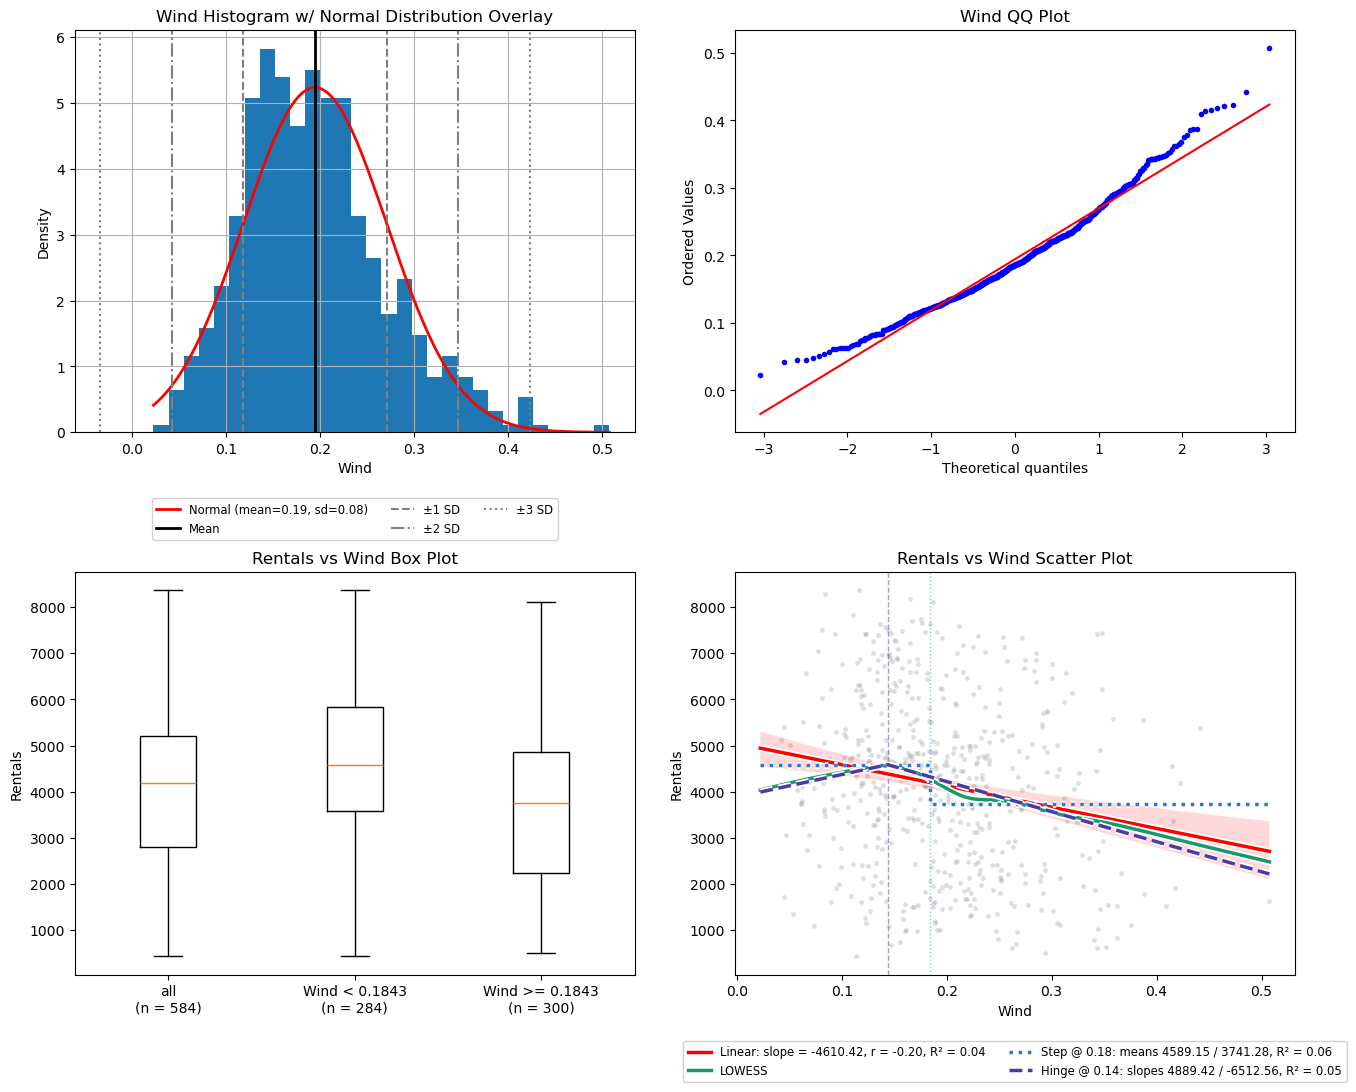

In [13]:
PLOTTING.single_feature_plots(df=train_df, feature='Wind', target=TARGET, threshold="auto");

### Notes / Observations

#### Noticeable Traits / Key Attributes

- **Moderately right skewed (0.668), mesokurtic (0.54).** The histogram peaks around 0.15 to 0.2 with a long right tail up to 0.507. In the QQ plot the high end rises above the line.
- **12 high outliers** above the 0.376 fence, and none below. In the scatter plot they sit along the downward trend, not away from it.
- **Weak negative relationship:** r = -0.196 (R² 0.04).
- **Mostly a gentle, steady decline.** LOWESS rises slightly up to about 0.14, then falls for the rest of the range, close to the straight line.
- **No shape clearly beats the line.** The hinge at 0.14 flips the slope from 4889.42 to -6512.56 but only reaches R² 0.05. The step at 0.18 (means 4589.15 / 3741.28) reaches R² 0.06. The line is at 0.04, and both thresholds were searched on the same rows, so gaps this small may not hold up.
- **The rising part is thin.** The bend at 0.14 is the 25% value (0.14), so only about a quarter of the rows sit below it.
- **Box plot:** the 284 rows below 0.1843 have a median Rentals of about 4,600, vs about 3,750 for the 300 rows at or above it. The two boxes overlap heavily.

#### Special Treatment

Candidates, ranked by expected benefit:

1. **Keep the raw value, untransformed.** The straight line is already close to LOWESS over most of the range, and no other fit gains more than 0.02 in R².
2. **An indicator for high values:** `1[x >= 0.18]`. The step has the highest R² of the fits (0.06) and splits the rows almost evenly (284 / 300), but the gain is small and optimistic.
3. **Drop the attribute** if it does not improve the model. On its own it explains little (R² 0.04).

- **Avoid log, square root and Yeo-Johnson.** They fix the skew by compressing the high tail, which is where Rentals are lowest, and by stretching the low end, where the relationship is flat or slightly rising.
- **Avoid clipping the 12 high outliers.** They follow the trend, so capping them at 0.376 removes part of the signal.
- **Avoid a hinge.** It spends two slopes to move R² from 0.04 to 0.05, and the rising slope (4889.42) rests on about a quarter of the rows.

# Statistical Values: Categorical Attributes

## How to Read the Table and Plots (applies to every categorical attribute below)

- **Levels are shown as the codes stored in the file.** A code is a label, not a quantity.
- **Level table:** one row per level, with the number of train rows at that level and the Rentals mean, median, std, min and max within it. `mean - overall mean` is the level's Rentals mean minus the Rentals mean of all train rows.
  - The `rows` column adds up to the 584 train rows for every attribute below, so none of them has a missing value.
- **Rows per level (bar chart):** how the train rows are spread across the levels. A level with few rows gives a less reliable mean.
- **Box plot:** Rentals for the rows at each level. The red diamond is the level mean and the dashed line is the overall mean. The further apart the boxes, the more the attribute says about Rentals.
- **Level means R² (box plot title):** the share of the variance in Rentals explained by predicting every row with its level's mean. This is what a one-hot encoded attribute can give a linear regression, so it can be compared with the R² values in the scatter plot legends above.
  - It is scored on the same rows the level means come from, so it is optimistic, more so for an attribute with many levels.

## Year

In [14]:
Q2_STATISTICS.category_levels_df(df=train_df, feature='Year', target=TARGET)

,rows,% of rows,Rentals mean,Rentals median,Rentals std,Rentals min,Rentals max,mean - overall mean
Year,,,,,,,,
0,365,62.5,3405.762,3740.0,1378.754,431,6043,-747.838
1,219,37.5,5399.995,5823.0,1699.125,1027,8362,1246.396


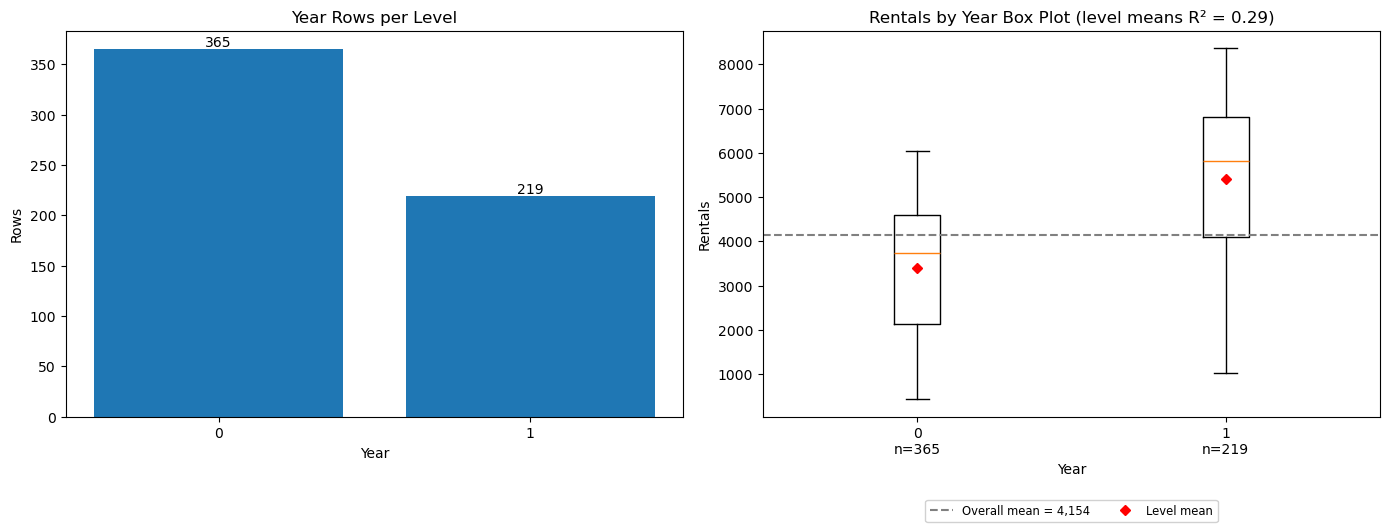

In [15]:
Q2_PLOTTING.categorical_feature_plots(df=train_df, feature='Year', target=TARGET);

### Notes / Observations

#### Noticeable Traits / Key Attributes

- **Clear shift between the two levels:** level means R² = 0.29 from one 0 / 1 column. The mean is 3,406 at level 0 and 5,400 at level 1.
- **Level 1 is a partial year:** 219 rows against 365, since train ends on 2012-08-06.
- **Every test row is at level 1** (the test period is 2012-08-07 to 2012-12-31), so this column decides which Rentals level the test predictions start from.

#### Special Treatment

- **Keep it as it is.** It is already a 0 / 1 indicator, so it needs no encoding.
- **Validation folds must train on rows from both levels.** A fold that trains on level 0 rows only sees a single value in this column and cannot learn the shift.

## Season (with Year Context)

In [16]:
Q2_STATISTICS.category_levels_df(df=train_df, feature='Season', target=TARGET)

,rows,% of rows,Rentals mean,Rentals median,Rentals std,Rentals min,Rentals max,mean - overall mean
Season,,,,,,,,
1,170,29.110,2651.412,2296.0,1412.458,431,7836,-1502.188
2,184,31.507,4992.332,4941.5,1695.977,795,8362,838.732
3,141,24.144,5178.979,4840.0,1294.236,1115,8173,1025.379
4,89,15.240,3664.461,3717.0,983.006,627,5511,-489.139


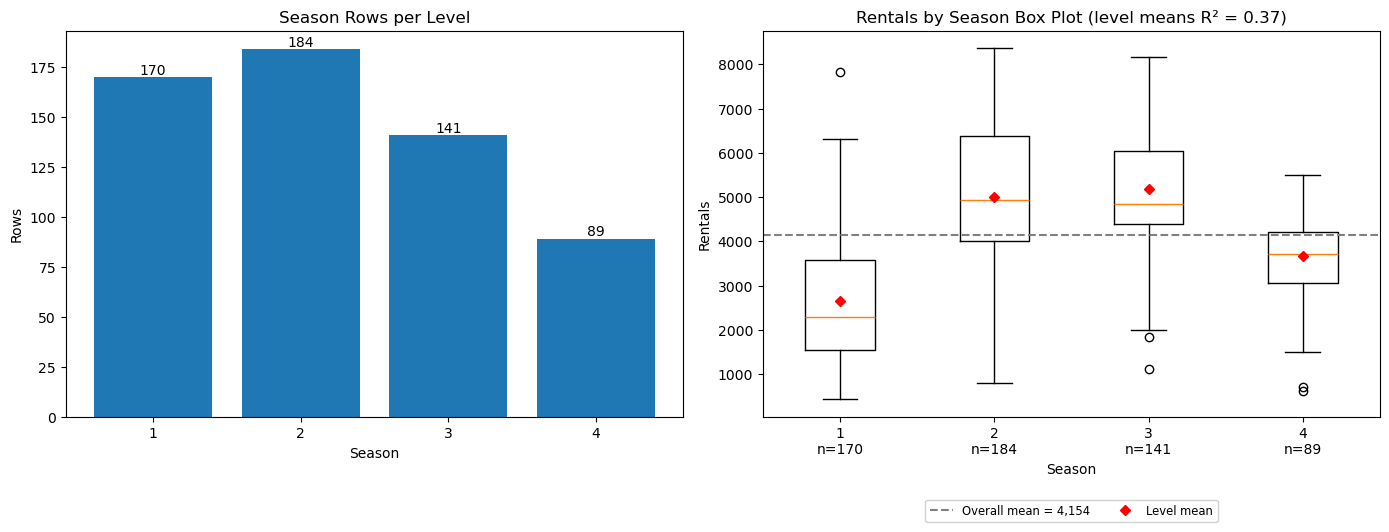

In [17]:
Q2_PLOTTING.categorical_feature_plots(df=train_df, feature='Season', target=TARGET);

### Year Context

**Why this table uses two attributes.** The rest of this notebook compares one attribute with Rentals. Here that view is misleading: train holds all of the first year and only part of the second (to 2012-08-06), so the Season levels are not spread evenly over the two years, and the second year runs higher (see the Year section above). The table splits each level by `Year` to separate the two effects.

- **rows / Rentals mean (Year 0, Year 1):** the train rows and the Rentals mean at each level within each year. The mean is empty where a level has no rows in that year.
- **Year 1 mean - Year 0 mean:** how much higher the second year runs at that level.

In [18]:
rows = pd.crosstab(train_df['Season'], train_df['Year'])
means = train_df.pivot_table(index='Season', columns='Year', values=TARGET, aggfunc='mean')

pd.DataFrame({
	'rows (Year 0)': rows[0],
	'rows (Year 1)': rows[1],
	f'{TARGET} mean (Year 0)': means[0],
	f'{TARGET} mean (Year 1)': means[1],
	'Year 1 mean - Year 0 mean': means[1] - means[0],
}).round(3)

,rows (Year 0),rows (Year 1),Rentals mean (Year 0),Rentals mean (Year 1),Year 1 mean - Year 0 mean
Season,,,,,
1,90,80,1666.667,3759.250,2092.583
2,92,92,3775.174,6209.489,2434.315
3,94,47,4464.362,6608.213,2143.851
4,89,0,3664.461,NaN,NaN


### Notes / Observations

#### Noticeable Traits / Key Attributes

- **Clear relationship, but not in code order:** level means R² = 0.37, with means of 2,651 / 4,992 / 5,179 / 3,664 for levels 1 to 4.
- **Level 4 only has first-year rows** (89 in Year 0, none in Year 1), and level 3 has half as many in Year 1 (47 against 94). So the level table compares a first-year mean at level 4 with means that blend both years.
- **Inside one year the picture changes.** In Year 0 the means run 1,667 / 3,775 / 4,464 / 3,664. Level 4 is about level with level 2, and level 3 is clearly above level 2 (also 6,608 against 6,209 in Year 1).
- **The second year adds about the same amount at every level:** 2092.583, 2434.315 and 2143.851 for levels 1 to 3.
- **Any second-year level 4 row is in the test period** (2012-08-07 to 2012-12-31). Train has none.

#### Special Treatment

- **One-hot encode:** one 0 / 1 column per level, with one level left out as the baseline (3 columns for the 4 levels).
- **Keep `Year` in the model with it.** The year shift is about the same at each level, so one `Year` column can carry it. Without it, the level 4 column absorbs the lower first year.
- **Avoid using the code as a number,** since the means rise and then fall.
- **Avoid merging levels 2 and 3.** They only look alike in the level table.

## Month (with Year Context)

In [19]:
Q2_STATISTICS.category_levels_df(df=train_df, feature='Month', target=TARGET)

,rows,% of rows,Rentals mean,Rentals median,Rentals std,Rentals min,Rentals max,mean - overall mean
Month,,,,,,,,
1,62,10.616,2176.339,1939.0,1161.674,431,4521,-1977.261
2,57,9.760,2655.298,2402.0,1145.313,1005,5062,-1498.301
3,62,10.616,3692.258,3216.5,1899.302,605,8362,-461.341
4,60,10.274,4484.900,4293.5,1776.161,795,7460,331.301
5,62,10.616,5349.774,4890.5,1298.712,2633,8294,1196.175
6,60,10.274,5772.367,5308.5,1240.400,3767,8120,1618.767
7,62,10.616,5563.677,5446.5,1273.752,3285,8173,1410.078
8,37,6.336,4811.027,4694.0,1216.343,1115,7580,657.428
9,30,5.137,4247.267,4584.5,965.377,1842,5423,93.667


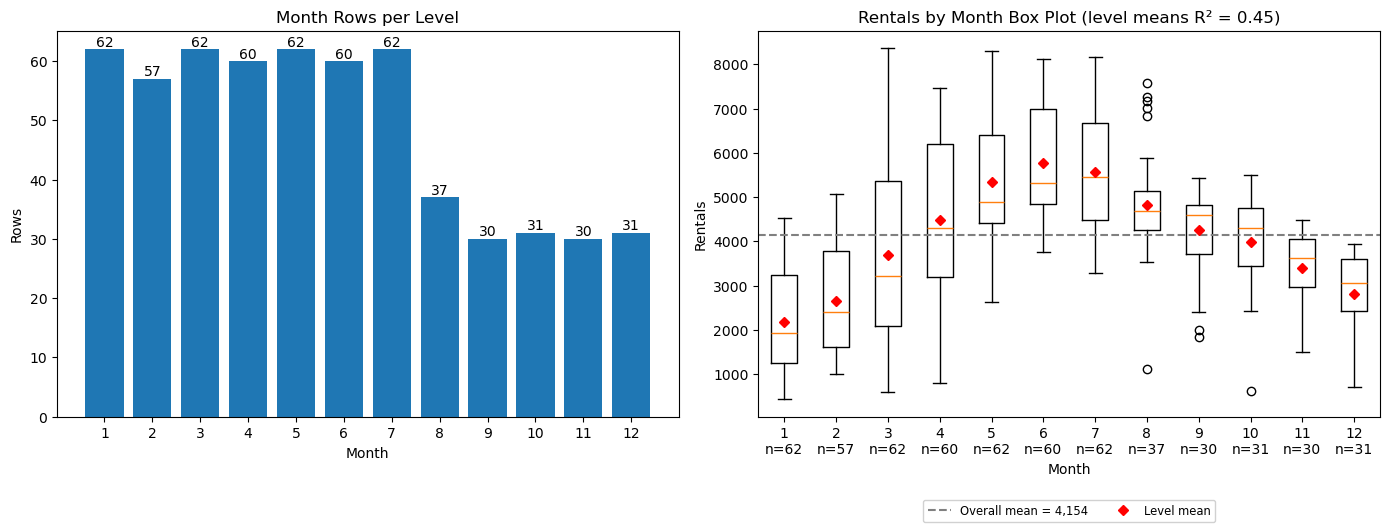

In [20]:
Q2_PLOTTING.categorical_feature_plots(df=train_df, feature='Month', target=TARGET);

### Year Context

**Why this table uses two attributes.** The rest of this notebook compares one attribute with Rentals. Here that view is misleading: train holds all of the first year and only part of the second (to 2012-08-06), so the Month levels are not spread evenly over the two years, and the second year runs higher (see the Year section above). The table splits each level by `Year` to separate the two effects.

- **rows / Rentals mean (Year 0, Year 1):** the train rows and the Rentals mean at each level within each year. The mean is empty where a level has no rows in that year.
- **Year 1 mean - Year 0 mean:** how much higher the second year runs at that level.

In [21]:
rows = pd.crosstab(train_df['Month'], train_df['Year'])
means = train_df.pivot_table(index='Month', columns='Year', values=TARGET, aggfunc='mean')

pd.DataFrame({
	'rows (Year 0)': rows[0],
	'rows (Year 1)': rows[1],
	f'{TARGET} mean (Year 0)': means[0],
	f'{TARGET} mean (Year 1)': means[1],
	'Year 1 mean - Year 0 mean': means[1] - means[0],
}).round(3)

,rows (Year 0),rows (Year 1),Rentals mean (Year 0),Rentals mean (Year 1),Year 1 mean - Year 0 mean
Month,,,,,
1,31,31,1231.903,3120.774,1888.871
2,28,29,1721.964,3556.448,1834.484
3,31,31,2065.968,5318.548,3252.581
4,30,30,3162.333,5807.467,2645.133
5,31,31,4381.323,6318.226,1936.903
6,30,30,4783.733,6761.000,1977.267
7,31,31,4559.387,6567.968,2008.581
8,31,6,4409.387,6886.167,2476.780
9,30,0,4247.267,NaN,NaN


### Notes / Observations

#### Noticeable Traits / Key Attributes

- **Highest level means R² of the categorical attributes (0.45),** and the most optimistic, since it is spread over 12 levels.
- **One rise and fall:** the mean climbs from 2,176 at month 1 to 5,772 at month 6 and drops to 2,817 at month 12.
- **Months 9 to 12 only have first-year rows** (30 or 31 each, none in Year 1), and month 8 has 6 in Year 1. Months 1 to 7 have both years.
- **So the level table overstates the fall.** Inside Year 0 it is gentler (4,784 at month 6, 4,247 at month 9, 2,817 at month 12), and month 12 ends well above month 1 (1,232).
- **The second year is higher in every month that has both years,** by 1834.484 to 3252.581.
- **The test period (2012-08-07 to 2012-12-31) is the months train lacks in the second year:** the rest of month 8 and months 9 to 12.

#### Special Treatment

Candidates, ranked by expected benefit:

1. **One-hot encode:** one 0 / 1 column per month, with one month left out as the baseline (11 columns for the 12 months). It follows every month, but the columns for months 9 to 12 each rest on 30 or 31 rows.
2. **A cyclical encoding:** the sine and cosine of the month (2 columns). Far fewer columns, and each month borrows from its neighbors. It assumes month 12 ends where month 1 starts, which Year 0 does not quite do (2,817 against 1,232).

- **Keep `Year` in the model with it.** Without it, the columns for months 9 to 12 absorb the lower first year.
- **Avoid using the code as a number,** since the means rise and then fall.

## Weekday

In [22]:
Q2_STATISTICS.category_levels_df(df=train_df, feature='Weekday', target=TARGET)

,rows,% of rows,Rentals mean,Rentals median,Rentals std,Rentals min,Rentals max,mean - overall mean
Weekday,,,,,,,,
0,84,14.384,3997.417,4032.0,1795.027,605,7641,-156.183
1,84,14.384,4051.738,4092.0,1627.219,1000,7105,-101.861
2,83,14.212,4211.892,4451.0,1676.713,683,7592,58.292
3,83,14.212,4085.711,4186.0,1843.334,506,8173,-67.888
4,83,14.212,4271.048,4189.0,1794.236,431,7494,117.449
5,83,14.212,4290.012,4151.0,1747.653,1167,8362,136.413
6,84,14.384,4170.286,4257.0,2049.309,627,8294,16.686


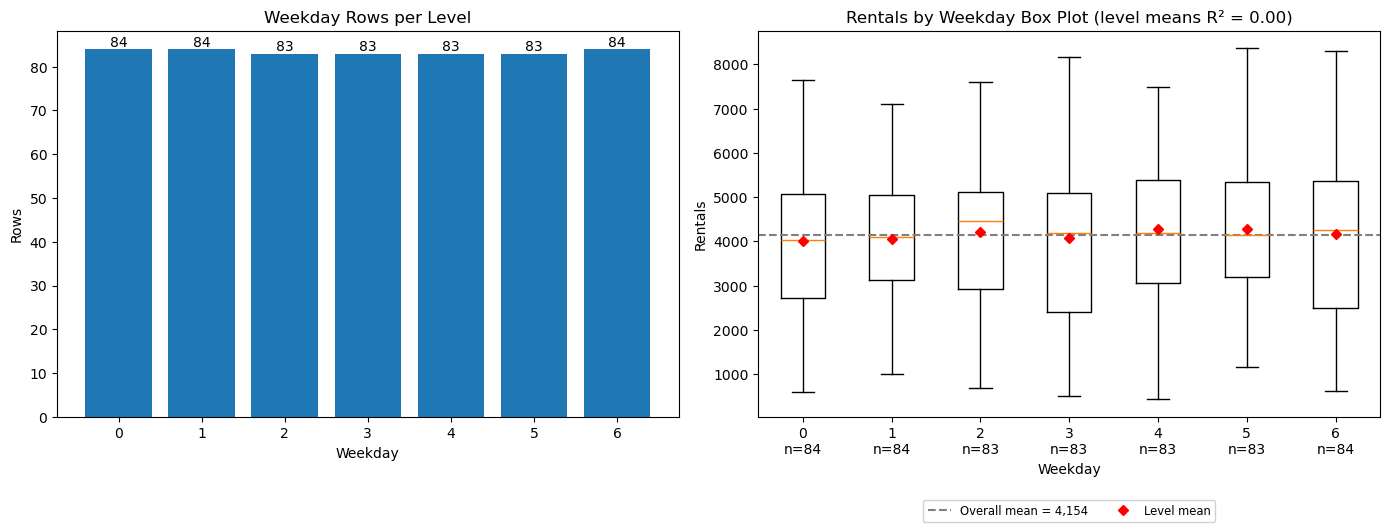

In [23]:
Q2_PLOTTING.categorical_feature_plots(df=train_df, feature='Weekday', target=TARGET);

### Notes / Observations

#### Noticeable Traits / Key Attributes

- **No relationship with Rentals:** level means R² = 0.00. The means run from 3,997 to 4,290, and the largest gap from the overall mean is -156.183.
- **The levels are evenly filled** (83 or 84 rows each), so the flat means are not a matter of too few rows.

#### Special Treatment

Candidates, ranked by expected benefit:

1. **Drop the attribute,** after checking that the model is no worse without it.
2. **If kept, use one numeric column, not one-hot.** One-hot spends 6 columns on gaps of at most 156.183.

## IsWorkday

In [24]:
Q2_STATISTICS.category_levels_df(df=train_df, feature='IsWorkday', target=TARGET)

,rows,% of rows,Rentals mean,Rentals median,Rentals std,Rentals min,Rentals max,mean - overall mean
IsWorkday,,,,,,,,
0,184,31.507,4039.690,4108.0,1935.064,605,8294,-113.909
1,400,68.493,4205.998,4268.0,1717.480,431,8362,52.398


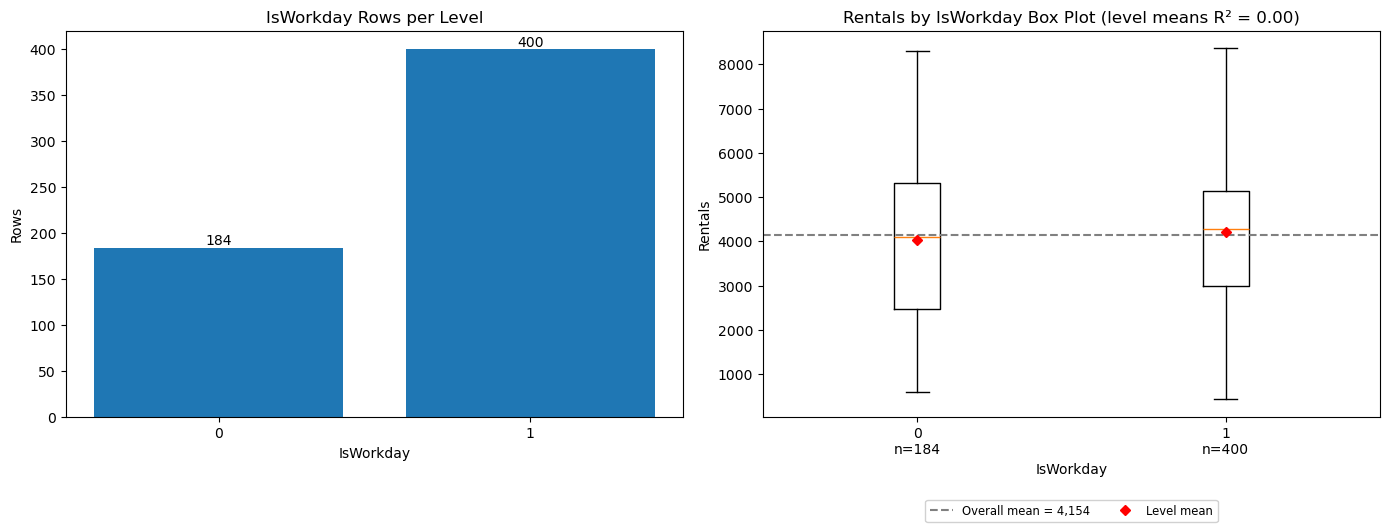

In [25]:
Q2_PLOTTING.categorical_feature_plots(df=train_df, feature='IsWorkday', target=TARGET);

### Notes / Observations

#### Noticeable Traits / Key Attributes

- **No relationship with Rentals:** level means R² = 0.00. The means are 4,040 and 4,206.
- **Both levels are well filled** (184 and 400 rows), so the small gap is not a matter of too few rows.

#### Special Treatment

Candidates, ranked by expected benefit:

1. **Drop the attribute,** after checking that the model is no worse without it.
2. **If kept, leave it as it is.** It is already a 0 / 1 indicator.

## IsHoliday

In [26]:
Q2_STATISTICS.category_levels_df(df=train_df, feature='IsHoliday', target=TARGET)

,rows,% of rows,Rentals mean,Rentals median,Rentals std,Rentals min,Rentals max,mean - overall mean
IsHoliday,,,,,,,,
0,568,97.26,4169.87,4262.0,1779.748,431,8362,16.270
1,16,2.74,3576.00,3240.0,2068.932,1000,7403,-577.599


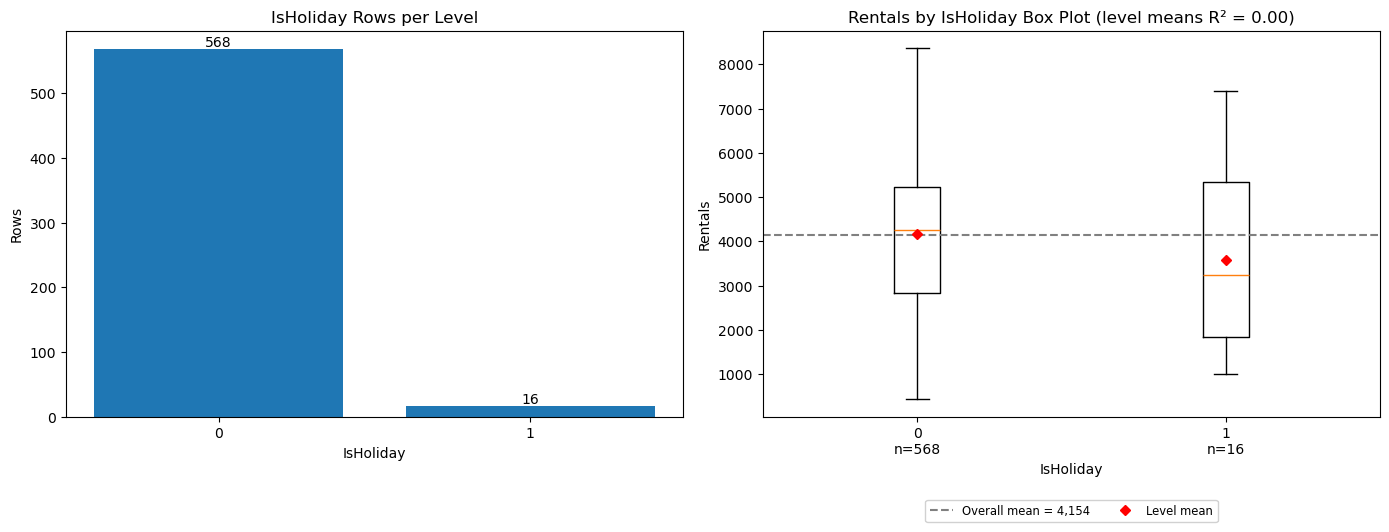

In [27]:
Q2_PLOTTING.categorical_feature_plots(df=train_df, feature='IsHoliday', target=TARGET);

### Notes / Observations

#### Noticeable Traits / Key Attributes

- **Only 16 rows at level 1** (2.74%), against 568 at level 0.
- **No measurable relationship with Rentals:** level means R² = 0.00. The mean is lower at level 1 (3,576 against 4,170), but those 16 rows span 1,000 to 7,403.

#### Special Treatment

Candidates, ranked by expected benefit:

1. **Leave it in as it is.** It is already a 0 / 1 indicator and costs one column.
2. **Drop it if it does not improve the model.** 16 rows are too few to pin its effect down, and a validation fold may hold almost none of them.

## Weather

In [28]:
Q2_STATISTICS.category_levels_df(df=train_df, feature='Weather', target=TARGET)

,rows,% of rows,Rentals mean,Rentals median,Rentals std,Rentals min,Rentals max,mean - overall mean
Weather,,,,,,,,
1,377,64.555,4509.897,4586.0,1742.077,431,8294,356.297
2,189,32.363,3665.101,3747.0,1656.598,605,8362,-488.499
3,18,3.082,1820.389,1829.5,1020.114,506,4459,-2333.210


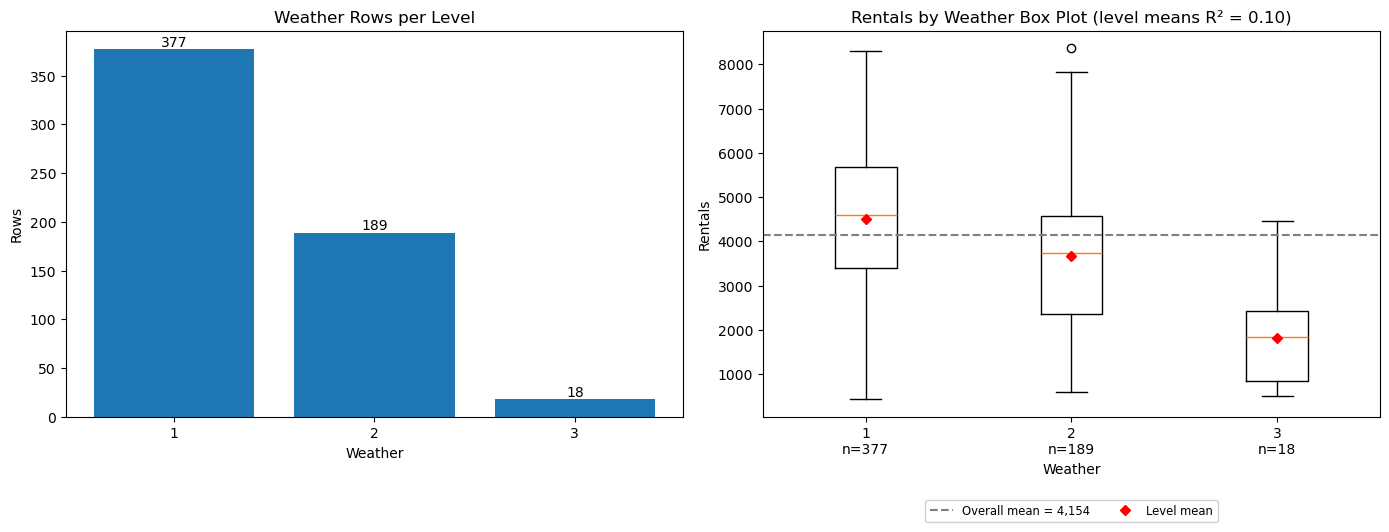

In [29]:
Q2_PLOTTING.categorical_feature_plots(df=train_df, feature='Weather', target=TARGET);

### Notes / Observations

#### Noticeable Traits / Key Attributes

- **Weak relationship with Rentals:** level means R² = 0.10.
- **Rentals fall as the code rises, in unequal steps:** means of 4,510 / 3,665 / 1,820 for levels 1 to 3.
- **Level 3 has the largest effect and the fewest rows:** a `mean - overall mean` of -2333.210 on 18 rows (3.082%). Its max (4,459) is far below those of levels 1 and 2 (8,294 and 8,362).

#### Special Treatment

Candidates, ranked by expected benefit:

1. **One-hot encode:** one 0 / 1 column per level, with one level left out as the baseline (2 columns for the 3 levels). The larger drop at level 3 gets its own coefficient.
2. **Leave the code as one numeric column.** The means are in code order, so one coefficient gets the direction right. It assumes equal steps, so it understates level 3.

- **Avoid merging level 3 into level 2.** Its mean (1,820) is far from level 2's (3,665), so merging hides the largest effect.

# Columns Without a Section

In [30]:
print(f"ID: {train_df['ID'].nunique()} distinct values in {len(train_df)} train rows, from {train_df['ID'].min()} to {train_df['ID'].max()}.")
print(f"Date: {train_df['Date'].nunique()} distinct values in {len(train_df)} train rows.")
print(f"Casual + Registered equals {TARGET} in every train row: {(train_df['Casual'] + train_df['Registered'] == train_df[TARGET]).all()}")

ID: 584 distinct values in 584 train rows, from 1 to 584.
Date: 584 distinct values in 584 train rows.
Casual + Registered equals Rentals in every train row: True


These four columns do not get a section of their own:

- **`ID`:** a row counter with 584 distinct values in 584 train rows (1 to 584). It labels the row and is not a measurement.
- **`Date`:** one distinct value per train row, so on its own it cannot be summarized like the attributes above. `Year`, `Month` and `Weekday` already describe the date.
- **`Casual` and `Registered`:** they add up to `Rentals` in every train row. They are the two parts of the target, so using them as attributes would give the answer away.

#### Special Treatment

- **Do not use `Casual` or `Registered` as attributes.**
- **Do not use `ID` or `Date` as they are.**